In [2]:

import torch
import torch.nn as nn
import torch.optim as optim
from collections import Counter
import re
import random

# ------------------------------
# 1. Preprocess Corpus
# ------------------------------
def tokenize(text):
    # very simple tokenizer: lowercase + split on non-letters
    return re.findall(r"\b\w+\b", text.lower())

corpus = """Natural language processing enables computers to understand human language.
Word embeddings map words into continuous vector space.
Neural networks can be used to learn these embeddings from context words in a document
corpus."""
tokens = tokenize(corpus)

# ------------------------------
# 2. Build Vocabulary
# ------------------------------
word_counts = Counter(tokens)
vocab = {w: i for i, (w, _) in enumerate(word_counts.items())}
id2word = {i: w for w, i in vocab.items()}
vocab_size = len(vocab)

# ------------------------------
# 3. Generate Training Data (Skip-gram)
# ------------------------------
def generate_pairs(tokens, window_size=2):
    pairs = []
    for i, center in enumerate(tokens):
        for j in range(max(0, i - window_size), min(len(tokens), i + window_size + 1)):
            if i != j:
                pairs.append((center, tokens[j]))
    return pairs

pairs = generate_pairs(tokens, window_size=2)
print("Sample training pairs:", pairs[:10])

# Convert to indices
training_data = [(vocab[c], vocab[o]) for c, o in pairs]

# ------------------------------
# 4. Define Neural Network
# ------------------------------
class Word2Vec(nn.Module):
    def __init__(self, vocab_size, embed_dim):
        super(Word2Vec, self).__init__()
        self.embeddings = nn.Embedding(vocab_size, embed_dim) # input layer
        self.output = nn.Linear(embed_dim, vocab_size)  # output layer

    def forward(self, center_word):
        embed = self.embeddings(center_word)
        out = self.output(embed)
        return out

# ------------------------------
# 5. Training
# ------------------------------
embed_dim = 50
model = Word2Vec(vocab_size, embed_dim)

criterion = nn.CrossEntropyLoss()
optimizer = optim.Adam(model.parameters(), lr=0.01)

for epoch in range(50):
    total_loss = 0
    for center, context in training_data:
        center_tensor = torch.tensor([center], dtype=torch.long)
        context_tensor = torch.tensor([context], dtype=torch.long)

        optimizer.zero_grad()
        output = model(center_tensor)
        loss = criterion(output, context_tensor)
        loss.backward()
        optimizer.step()
        total_loss += loss.item()

    if (epoch+1) % 10 == 0:
        print(f"Epoch {epoch+1}, Loss: {total_loss:.4f}")

# ------------------------------
# 6. Extract Word Embeddings
# ------------------------------
embeddings = model.embeddings.weight.data
print("\nWord Embedding for 'language':\n", embeddings[vocab["language"]])
print("\nWord Embedding for 'neural':\n", embeddings[vocab["neural"]])


Sample training pairs: [('natural', 'language'), ('natural', 'processing'), ('language', 'natural'), ('language', 'processing'), ('language', 'enables'), ('processing', 'natural'), ('processing', 'language'), ('processing', 'enables'), ('processing', 'computers'), ('enables', 'language')]
Epoch 10, Loss: 266.7777
Epoch 20, Loss: 246.0085
Epoch 30, Loss: 239.3556
Epoch 40, Loss: 237.1559
Epoch 50, Loss: 231.9492

Word Embedding for 'language':
 tensor([-8.0031e-01, -9.2265e-04, -4.5435e-01, -4.0060e-01,  5.3182e-01,
        -2.7137e-02,  4.1251e-01,  4.1832e-02, -6.3019e-01,  1.1484e+00,
        -9.9825e-02,  5.5756e-01,  4.9259e-01,  6.8181e-01,  1.0689e-01,
        -4.2400e-01,  1.4447e-01, -1.4868e-01,  4.6431e-02,  2.4480e-01,
        -3.0948e-01,  2.4622e-01,  3.4438e-02, -2.5522e-01, -7.8864e-02,
        -2.9575e-01, -6.2257e-02,  9.7229e-01, -4.8773e-03, -2.0392e-01,
        -2.8896e-01,  1.8016e-01,  2.2024e-02,  3.1648e-02,  8.0719e-01,
         1.4797e-02, -3.8093e-01,  4.7337

In [3]:

import torch
import torch.nn as nn
import torch.optim as optim
from sklearn.datasets import load_iris
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

# ------------------------------
# 1. Load Dataset (Iris)
# ------------------------------
iris = load_iris()
X = iris.data # features
y = iris.target # labels (0, 1, 2)

# Normalize features
scaler = StandardScaler()
X = scaler.fit_transform(X)

# Convert to torch tensors
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)
X_train = torch.tensor(X_train, dtype=torch.float32)
y_train = torch.tensor(y_train, dtype=torch.long)
X_test = torch.tensor(X_test, dtype=torch.float32)
y_test = torch.tensor(y_test, dtype=torch.long)

# ------------------------------
# 2. Define Deep Neural Network
# ------------------------------
class DeepNN(nn.Module):
    def __init__(self, input_size, hidden1, hidden2, num_classes):
        super(DeepNN, self).__init__()
        self.fc1 = nn.Linear(input_size, hidden1) # input → hidden1
        self.relu1 = nn.ReLU()
        self.fc2 = nn.Linear(hidden1, hidden2) # hidden1 → hidden2
        self.relu2 = nn.ReLU()
        self.fc3 = nn.Linear(hidden2, num_classes) # hidden2 → output

    def forward(self, x):
        out = self.fc1(x)
        out = self.relu1(out)
        out = self.fc2(out)
        out = self.relu2(out)
        out = self.fc3(out)
        return out

# ------------------------------
# 3. Initialize Model
# ------------------------------
input_size = X.shape[1] # 4 features
hidden1, hidden2 = 16, 8
num_classes = 3 # iris has 3 classes
model = DeepNN(input_size, hidden1, hidden2, num_classes)

# Loss and optimizer
criterion = nn.CrossEntropyLoss()
optimizer = optim.Adam(model.parameters(), lr=0.01)

# ------------------------------
# 4. Training
# ------------------------------
epochs = 100
for epoch in range(epochs):
    # Forward pass
    outputs = model(X_train)
    loss = criterion(outputs, y_train)

    # Backward pass
    optimizer.zero_grad()
    loss.backward()
    optimizer.step()

    if (epoch+1) % 10 == 0:
        print(f"Epoch [{epoch+1}/{epochs}], Loss: {loss.item():.4f}")

# ------------------------------
# 5. Evaluation
# ------------------------------
with torch.no_grad():
    test_outputs = model(X_test)
    _, predicted = torch.max(test_outputs, 1)
    accuracy = (predicted == y_test).sum().item() / y_test.size(0)

print("\nClassification Accuracy on Test Data: {:.2f}%".format(accuracy * 100))


Epoch [10/100], Loss: 1.0226
Epoch [20/100], Loss: 0.7541
Epoch [30/100], Loss: 0.4146
Epoch [40/100], Loss: 0.2079
Epoch [50/100], Loss: 0.1133
Epoch [60/100], Loss: 0.0749
Epoch [70/100], Loss: 0.0612
Epoch [80/100], Loss: 0.0545
Epoch [90/100], Loss: 0.0508
Epoch [100/100], Loss: 0.0484

Classification Accuracy on Test Data: 100.00%


In [4]:

import torch
import torch.nn as nn
import torch.optim as optim
import torch.nn.functional as F
import torchvision
import torchvision.transforms as transforms

# ------------------------------
# 1. Load Dataset (MNIST)
# ------------------------------
transform = transforms.Compose([transforms.ToTensor()])

train_dataset = torchvision.datasets.MNIST(root='./data', train=True,
                       download=True, transform=transform)
test_dataset = torchvision.datasets.MNIST(root='./data', train=False,
                       download=True, transform=transform)

train_loader = torch.utils.data.DataLoader(dataset=train_dataset,
                       batch_size=64, shuffle=True)
test_loader = torch.utils.data.DataLoader(dataset=test_dataset,
                       batch_size=64, shuffle=False)

# ------------------------------
# 2. Define CNN Model
# ------------------------------
class CNN(nn.Module):
    def __init__(self):
        super(CNN, self).__init__()
        self.conv1 = nn.Conv2d(1, 16, kernel_size=3, padding=1) # 1→16
        self.pool = nn.MaxPool2d(2, 2)
        self.conv2 = nn.Conv2d(16, 32, kernel_size=3, padding=1) # 16→32
        self.fc1 = nn.Linear(32 * 7 * 7, 128)
        self.fc2 = nn.Linear(128, 10) # 10 classes (digits 0-9)

    def forward(self, x):
        x = self.pool(F.relu(self.conv1(x))) # [1,28,28] → [16,14,14]
        x = self.pool(F.relu(self.conv2(x))) # [16,14,14] → [32,7,7]
        x = x.view(-1, 32 * 7 * 7) # flatten
        x = F.relu(self.fc1(x))
        x = self.fc2(x)
        return x

# ------------------------------
# 3. Initialize Model
# ------------------------------
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
model = CNN().to(device)
criterion = nn.CrossEntropyLoss()
optimizer = optim.Adam(model.parameters(), lr=0.001)

# ------------------------------
# 4. Training
# ------------------------------
epochs = 5
for epoch in range(epochs):
    running_loss = 0.0
    for images, labels in train_loader:
        images, labels = images.to(device), labels.to(device)

        optimizer.zero_grad()
        outputs = model(images)
        loss = criterion(outputs, labels)
        loss.backward()
        optimizer.step()

        running_loss += loss.item()
    print(f"Epoch {epoch+1}/{epochs}, Loss: {running_loss/len(train_loader):.4f}")

# ------------------------------
# 5. Evaluation
# ------------------------------
correct, total = 0, 0
with torch.no_grad():
    for images, labels in test_loader:
        images, labels = images.to(device), labels.to(device)
        outputs = model(images)
        _, predicted = torch.max(outputs, 1)
        total += labels.size(0)
        correct += (predicted == labels).sum().item()

print(f"\nTest Accuracy: {100 * correct / total:.2f}%")


100%|██████████| 9.91M/9.91M [00:06<00:00, 1.46MB/s]
100%|██████████| 28.9k/28.9k [00:00<00:00, 36.6kB/s]
100%|██████████| 1.65M/1.65M [00:04<00:00, 359kB/s] 
100%|██████████| 4.54k/4.54k [00:00<00:00, 10.3MB/s]


Epoch 1/5, Loss: 0.2227
Epoch 2/5, Loss: 0.0623
Epoch 3/5, Loss: 0.0426
Epoch 4/5, Loss: 0.0325
Epoch 5/5, Loss: 0.0247

Test Accuracy: 98.85%


Epoch 1/10, Loss: 0.0609
Epoch 2/10, Loss: 0.0311
Epoch 3/10, Loss: 0.0251
Epoch 4/10, Loss: 0.0217
Epoch 5/10, Loss: 0.0191
Epoch 6/10, Loss: 0.0177
Epoch 7/10, Loss: 0.0165
Epoch 8/10, Loss: 0.0154
Epoch 9/10, Loss: 0.0145
Epoch 10/10, Loss: 0.0138


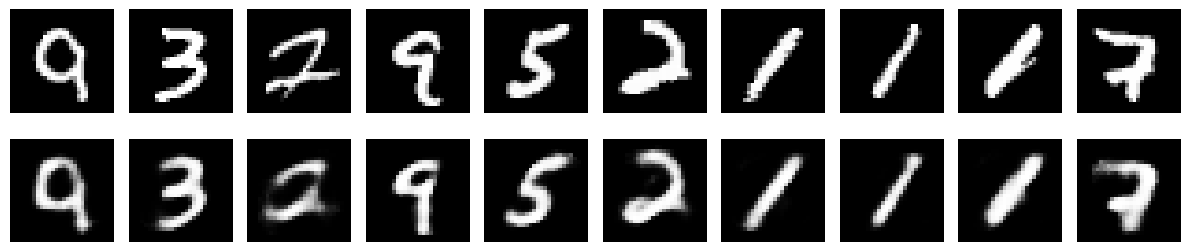

In [7]:

import torch
import torch.nn as nn
import torch.optim as optim
import torchvision
import torchvision.transforms as transforms
import matplotlib.pyplot as plt

# ------------------------------
# 1. Load Dataset (MNIST)
# ------------------------------
transform = transforms.Compose([transforms.ToTensor()])

train_dataset = torchvision.datasets.MNIST(
    root='./data',
    train=True,
    download=True,
    transform=transform
)

train_loader = torch.utils.data.DataLoader(
    dataset=train_dataset,
    batch_size=128,
    shuffle=True
)

# ------------------------------
# 2. Define Autoencoder
# ------------------------------
class Autoencoder(nn.Module):
    def __init__(self):
        super(Autoencoder, self).__init__()

        # Encoder (compression)
        self.encoder = nn.Sequential(
            nn.Linear(28 * 28, 128),
            nn.ReLU(True),
            nn.Linear(128, 64),
            nn.ReLU(True),
            nn.Linear(64, 32)  # Compressed representation
        )

        # Decoder (reconstruction)
        self.decoder = nn.Sequential(
            nn.Linear(32, 64),
            nn.ReLU(True),
            nn.Linear(64, 128),
            nn.ReLU(True),
            nn.Linear(128, 28 * 28),
            nn.Sigmoid()  # Output values between 0 and 1
        )

    def forward(self, x):
        x = self.encoder(x)
        x = self.decoder(x)
        return x


# ------------------------------
# 3. Initialize Model
# ------------------------------
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

model = Autoencoder().to(device)
criterion = nn.MSELoss()
optimizer = optim.Adam(model.parameters(), lr=0.001)

# ------------------------------
# 4. Training
# ------------------------------
epochs = 10

for epoch in range(epochs):
    model.train()
    running_loss = 0.0

    for images, _ in train_loader:
        images = images.view(-1, 28 * 28).to(device)

        optimizer.zero_grad()

        outputs = model(images)
        loss = criterion(outputs, images)

        loss.backward()
        optimizer.step()

        running_loss += loss.item()

    print(
        f"Epoch {epoch + 1}/{epochs}, "
        f"Loss: {running_loss / len(train_loader):.4f}"
    )

# ------------------------------
# 5. Demonstrate Compression & Reconstruction
# ------------------------------

# Get some test images
test_dataset = torchvision.datasets.MNIST(
    root='./data',
    train=False,
    download=True,
    transform=transform
)

test_loader = torch.utils.data.DataLoader(
    dataset=test_dataset,
    batch_size=10,
    shuffle=True
)

# Show original and reconstructed images
model.eval()

with torch.no_grad():
    images, _ = next(iter(test_loader))
    images = images.view(-1, 28 * 28).to(device)

    outputs = model(images)

    # Move to CPU and reshape
    images = images.view(-1, 1, 28, 28).cpu()
    outputs = outputs.view(-1, 1, 28, 28).cpu()

    # Plot original and reconstructed images
    fig, axes = plt.subplots(2, 10, figsize=(12, 3))

    for i in range(10):
        # Original image
        axes[0][i].imshow(images[i].squeeze(), cmap='gray')
        axes[0][i].axis("off")

        # Reconstructed image
        axes[1][i].imshow(outputs[i].squeeze(), cmap='gray')
        axes[1][i].axis("off")

    axes[0][0].set_ylabel("Original")
    axes[1][0].set_ylabel("Reconstructed")

    plt.tight_layout()
    plt.show()

In [8]:
pip install tensorflow scikit-learn numpy


[notice] A new release of pip is available: 26.1.2 -> 26.2.2
[notice] To update, run: pip install --upgrade pip
Note: you may need to restart the kernel to use updated packages.


In [10]:

import numpy as np
from sklearn.datasets import fetch_20newsgroups
from sklearn.model_selection import train_test_split

from tensorflow.keras.preprocessing.text import Tokenizer
from tensorflow.keras.preprocessing.sequence import pad_sequences
from tensorflow.keras.utils import to_categorical
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Embedding, LSTM, Dense

# Step 1: Loading dataset
print("Step 1: Loading dataset ...")

data = fetch_20newsgroups(subset='all')
texts, labels = data.data, data.target

num_classes = len(set(labels))

print(f"Loaded {len(texts)} documents across {num_classes} classes.")

# Step 2: Preprocessing text
print("\nStep 2: Preprocessing text ...")

MAX_WORDS = 10000  # Vocabulary size
MAX_LEN = 300      # Maximum tokens per document

tokenizer = Tokenizer(num_words=MAX_WORDS, oov_token="<OOV>")
tokenizer.fit_on_texts(texts)

X = tokenizer.texts_to_sequences(texts)
X = pad_sequences(X, maxlen=MAX_LEN)

y = to_categorical(labels, num_classes=num_classes)

print("Text converted to padded sequences.")

# Step 3: Splitting into train and test
print("\nStep 3: Splitting into train and test ...")

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

print(f"Training samples: {len(X_train)}, Testing samples: {len(X_test)}")

# Step 4: Building deep learning model
print("\nStep 4: Building deep learning model ...")

model = Sequential([
    Embedding(
        input_dim=MAX_WORDS,
        output_dim=128,
        input_length=MAX_LEN
    ),
    LSTM(128),
    Dense(num_classes, activation="softmax")
])

model.compile(
    loss="categorical_crossentropy",
    optimizer="adam",
    metrics=["accuracy"]
)

model.summary()

# Step 5: Training model
print("\nStep 5: Training model ...")

history = model.fit(
    X_train,
    y_train,
    epochs=5,
    batch_size=64,
    validation_split=0.1,
    verbose=2
)

# Step 6: Evaluating model on test set
print("\nStep 6: Evaluating model on test set ...")

loss, acc = model.evaluate(X_test, y_test, verbose=0)

print(f"Test Accuracy: {acc:.4f}")


Step 1: Loading dataset ...
Loaded 18846 documents across 20 classes.

Step 2: Preprocessing text ...
Text converted to padded sequences.

Step 3: Splitting into train and test ...
Training samples: 15076, Testing samples: 3770

Step 4: Building deep learning model ...


/opt/anaconda3/lib/python3.12/site-packages/keras/src/layers/core/embedding.py:103: UserWarning: Argument `input_length` is deprecated. Just remove it.
  warnings.warn(
2026-10-27 15:36:30.800984: I metal_plugin/src/device/metal_device.cc:1154] Metal device set to: Apple M3
2026-10-27 15:36:30.801312: I metal_plugin/src/device/metal_device.cc:296] systemMemory: 8.00 GB
2026-10-27 15:36:30.801391: I metal_plugin/src/device/metal_device.cc:313] maxCacheSize: 2.67 GB
2026-10-27 15:36:30.801602: I tensorflow/core/common_runtime/pluggable_device/pluggable_device_factory.cc:305] Could not identify NUMA node of platform GPU ID 0, defaulting to 0. Your kernel may not have been built with NUMA support.
2026-10-27 15:36:30.801794: I tensorflow/core/common_runtime/pluggable_device/pluggable_device_factory.cc:271] Created TensorFlow device (/job:localhost/replica:0/task:0/device:GPU:0 with 0 MB memory) -> physical PluggableDevice (device: 0, name: METAL, pci bus id: <undefined>)


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ embedding (Embedding)           │ ?                      │   0 (unbuilt) │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ lstm (LSTM)                     │ ?                      │   0 (unbuilt) │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ ?                      │   0 (unbuilt) │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 0 (0.00 B)

 Trainable params: 0 (0.00 B)

 Non-trainable params: 0 (0.00 B)


Step 5: Training model ...
Epoch 1/5


2026-10-27 15:36:32.763476: I tensorflow/core/grappler/optimizers/custom_graph_optimizer_registry.cc:117] Plugin optimizer for device_type GPU is enabled.


: 

In [2]:

import numpy as np
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import mean_squared_error, mean_absolute_error
import tensorflow as tf
from tensorflow.keras.models import Model
from tensorflow.keras.layers import Input, LSTM, Dense, TimeDistributed

# ---------------------------
# 1) Generate synthetic time series
# ---------------------------
def generate_series(n=1000):
    t = np.arange(n)
    trend = 0.01 * t
    seasonal = np.sin(2 * np.pi * t / 50)
    noise = 0.1 * np.random.randn(n)
    series = 10 + trend + seasonal + noise
    return series

series = generate_series(1000)

# ---------------------------
# 2) Scale data
# ---------------------------
scaler = StandardScaler()
series_scaled = scaler.fit_transform(
    series.reshape(-1, 1)
).flatten()

# ---------------------------
# 3) Windowing
# ---------------------------
INPUT_WINDOW = 30
OUTPUT_WINDOW = 10

def make_windows(data, input_w, output_w):
    X, Y = [], []

    for i in range(len(data) - input_w - output_w + 1):
        X.append(data[i:i + input_w])
        Y.append(data[i + input_w:i + input_w + output_w])

    return np.array(X), np.array(Y)

X, Y = make_windows(
    series_scaled, INPUT_WINDOW, OUTPUT_WINDOW
)

X = X[..., np.newaxis]
Y = Y[..., np.newaxis]

# Train/test split (80/20)
split = int(0.8 * len(X))

X_train, X_test = X[:split], X[split:]
Y_train, Y_test = Y[:split], Y[split:]

# ---------------------------
# 4) Build Seq2Seq LSTM model
# ---------------------------

# Encoder
encoder_inputs = Input(shape=(INPUT_WINDOW, 1))

encoder_lstm = LSTM(64, return_state=True)

encoder_outputs, state_h, state_c = encoder_lstm(
    encoder_inputs
)

encoder_states = [state_h, state_c]

# Decoder
decoder_inputs = Input(shape=(OUTPUT_WINDOW, 1))

decoder_lstm = LSTM(
    64,
    return_sequences=True,
    return_state=True
)

decoder_outputs, _, _ = decoder_lstm(
    decoder_inputs,
    initial_state=encoder_states
)

decoder_dense = TimeDistributed(Dense(1))
decoder_outputs = decoder_dense(decoder_outputs)

model = Model(
    [encoder_inputs, decoder_inputs],
    decoder_outputs
)

model.compile(
    optimizer='adam',
    loss='mse',
    metrics=['mae']
)

model.summary()

# Prepare decoder input (teacher forcing)
decoder_input_train = np.zeros_like(Y_train)
decoder_input_test = np.zeros_like(Y_test)

# ---------------------------
# 5) Train
# ---------------------------
history = model.fit(
    [X_train, decoder_input_train],
    Y_train,
    validation_data=(
        [X_test, decoder_input_test],
        Y_test
    ),
    epochs=20,
    batch_size=32,
    verbose=1
)

# ---------------------------
# 6) Evaluate
# ---------------------------
preds = model.predict(
    [X_test, decoder_input_test]
)

preds_unscaled = scaler.inverse_transform(
    preds.reshape(-1, 1)
).reshape(preds.shape)

Y_test_unscaled = scaler.inverse_transform(
    Y_test.reshape(-1, 1)
).reshape(Y_test.shape)

mae = mean_absolute_error(
    Y_test_unscaled.flatten(),
    preds_unscaled.flatten()
)

rmse = np.sqrt(
    mean_squared_error(
        Y_test_unscaled.flatten(),
        preds_unscaled.flatten()
    )
)

print(f"Test MAE: {mae:.4f}, Test RMSE: {rmse:.4f}")


Model: "functional_1"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ input_layer_2       │ (None, 30, 1)     │          0 │ -                 │
│ (InputLayer)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ input_layer_3       │ (None, 10, 1)     │          0 │ -                 │
│ (InputLayer)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ lstm_2 (LSTM)       │ [(None, 64),      │     16,896 │ input_layer_2[0]… │
│                     │ (None, 64),       │            │                   │
│                     │ (None, 64)]       │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ lstm_3 (LSTM)       │ [(None, 10, 64),  │     16,896 │ input_layer_3[0]… │
│                     │ (None, 64),       │            │ lstm_2[0][1],     │
│                     │ (None, 64)]       │            │ lstm_2[0][2]      │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ time_distributed_1  │ (None, 10, 1)     │         65 │ lstm_3[0][0]      │
│ (TimeDistributed)   │                   │            │                   │
└─────────────────────┴───────────────────┴────────────┴───────────────────┘

 Total params: 33,857 (132.25 KB)

 Trainable params: 33,857 (132.25 KB)

 Non-trainable params: 0 (0.00 B)

Epoch 1/20
24/24 ━━━━━━━━━━━━━━━━━━━━ 3s 70ms/step - loss: 0.3799 - mae: 0.4989 - val_loss: 0.8584 - val_mae: 0.8879
Epoch 2/20
24/24 ━━━━━━━━━━━━━━━━━━━━ 1s 26ms/step - loss: 0.0948 - mae: 0.2565 - val_loss: 0.1704 - val_mae: 0.3337
Epoch 3/20
24/24 ━━━━━━━━━━━━━━━━━━━━ 2s 67ms/step - loss: 0.0699 - mae: 0.2252 - val_loss: 0.2065 - val_mae: 0.3809
Epoch 4/20
24/24 ━━━━━━━━━━━━━━━━━━━━ 2s 72ms/step - loss: 0.0600 - mae: 0.2092 - val_loss: 0.1450 - val_mae: 0.3070
Epoch 5/20
24/24 ━━━━━━━━━━━━━━━━━━━━ 1s 33ms/step - loss: 0.0540 - mae: 0.1979 - val_loss: 0.1354 - val_mae: 0.2957
Epoch 6/20
24/24 ━━━━━━━━━━━━━━━━━━━━ 1s 22ms/step - loss: 0.0505 - mae: 0.1911 - val_loss: 0.1344 - val_mae: 0.2972
Epoch 7/20
24/24 ━━━━━━━━━━━━━━━━━━━━ 1s 23ms/step - loss: 0.0471 - mae: 0.1841 - val_loss: 0.1715 - val_mae: 0.3458
Epoch 8/20
24/24 ━━━━━━━━━━━━━━━━━━━━ 1s 22ms/step - loss: 0.0423 - mae: 0.1738 - val_loss: 0.1202 - val_mae: 0.2829
Epoch 9/20
24/24 ━━━━━━━━━━━━━━━━━━━━ 1s 24ms/step - loss: 0.036

In [3]:
pip install tensorflow


[notice] A new release of pip is available: 26.1.2 -> 26.2.2
[notice] To update, run: pip install --upgrade pip
Note: you may need to restart the kernel to use updated packages.


In [4]:

from tensorflow.keras.preprocessing.image import ImageDataGenerator
from tensorflow.keras.models import Model
from tensorflow.keras.layers import Dense, GlobalAveragePooling2D
from tensorflow.keras.applications import ResNet50
from tensorflow.keras.applications.resnet50 import preprocess_input

# 1) Dataset paths (adjust as required)
train_dir = "data/train"
val_dir = "data/val"

img_size = (224, 224)
batch_size = 32

# 2) Data generators
train_datagen = ImageDataGenerator(
    preprocessing_function=preprocess_input
)

val_datagen = ImageDataGenerator(
    preprocessing_function=preprocess_input
)

train_gen = train_datagen.flow_from_directory(
    train_dir,
    target_size=img_size,
    batch_size=batch_size,
    class_mode='categorical'
)

val_gen = val_datagen.flow_from_directory(
    val_dir,
    target_size=img_size,
    batch_size=batch_size,
    class_mode='categorical'
)

num_classes = train_gen.num_classes

# 3) Pre-trained model (ResNet50) without top layer
base_model = ResNet50(
    weights='imagenet',
    include_top=False,
    input_shape=(224, 224, 3)
)

base_model.trainable = False  # Freeze base model

# 4) Add classification head
x = base_model.output
x = GlobalAveragePooling2D()(x)
x = Dense(128, activation='relu')(x)
predictions = Dense(num_classes, activation='softmax')(x)

model = Model(
    inputs=base_model.input,
    outputs=predictions
)

# 5) Compile model
model.compile(
    optimizer='adam',
    loss='categorical_crossentropy',
    metrics=['accuracy']
)

# 6) Train model
model.fit(
    train_gen,
    validation_data=val_gen,
    epochs=5
)

# 7) Evaluate model
loss, acc = model.evaluate(val_gen)

print(f"Validation Loss: {loss:.4f}")
print(f"Validation Accuracy: {acc:.4f}")


FileNotFoundError: [Errno 2] No such file or directory: 'data/train'

In [ ]:

import random

class GridWorld:
    def __init__(self, width, height, start, goal, obstacles=None):
        # Initialize grid dimensions, start & goal positions, and obstacles
        self.width = width
        self.height = height
        self.start = start
        self.goal = goal
        self.obstacles = obstacles if obstacles is not None else []
        self.reset()

    def reset(self):
        # Reset the agent to the start position
        self.agent_pos = self.start
        return self.agent_pos

    def render(self):
        # Print the current grid with agent, start, goal, and obstacles
        for i in range(self.height):
            row = ''
            for j in range(self.width):
                if (i, j) == self.agent_pos:
                    row += 'A '
                elif (i, j) == self.start:
                    row += 'S '
                elif (i, j) == self.goal:
                    row += 'G '
                elif (i, j) in self.obstacles:
                    row += 'O '
                else:
                    row += '. '
            print(row)
        print()

    def step(self, action):
        # Move the agent in the given direction
        x, y = self.agent_pos

        if action == 'up':
            x -= 1
        elif action == 'down':
            x += 1
        elif action == 'left':
            y -= 1
        elif action == 'right':
            y += 1
        else:
            print("Invalid action! Use: up, down, left, right")
            return self.agent_pos, -0.01, False

        # Check if the new position is within grid boundaries
        if 0 <= x < self.height and 0 <= y < self.width:
            new_pos = (x, y)
        else:
            new_pos = self.agent_pos

        self.agent_pos = new_pos

        # Determine reward and whether the episode is done
        if new_pos == self.goal:
            reward = 1
            done = True
        elif new_pos in self.obstacles:
            reward = -1
            done = True
        else:
            reward = -0.01
            done = False

        return new_pos, reward, done


# -----------------------------
# User-controlled agent with RANDOM obstacles
# -----------------------------
width, height = 5, 5
start = (0, 0)
goal = (4, 4)

# Generate random obstacles (3 positions each run)
all_positions = [
    (i, j)
    for i in range(height)
    for j in range(width)
]

all_positions.remove(start)
all_positions.remove(goal)

obstacles = random.sample(all_positions, 3)

env = GridWorld(width, height, start, goal, obstacles)

state = env.reset()
done = False

print("Welcome to Grid World!\n")
print("Game Rules:")
print(" - Reach the Goal (G) to win!")
print(" - Avoid Obstacles (O), or you lose!")
print(" - You are the Agent (A), starting from Start (S)")
print(" - Use commands: up, down, left, right to move\n")

env.render()

while not done:
    action = input("Enter your move (up, down, left, right): ").strip().lower()

    state, reward, done = env.step(action)

    print(f"New State: {state}, Reward: {reward}")
    env.render()

if state == goal:
    print("Congratulations! You reached the goal!")
elif state in obstacles:
    print("Game Over! You hit an obstacle!")


Welcome to Grid World!

Game Rules:
 - Reach the Goal (G) to win!
 - Avoid Obstacles (O), or you lose!
 - You are the Agent (A), starting from Start (S)
 - Use commands: up, down, left, right to move

A . . . O 
. . . . . 
. . O . . 
. . O . . 
. . . . G 

Invalid action! Use: up, down, left, right
New State: (0, 0), Reward: -0.01
A . . . O 
. . . . . 
. . O . . 
. . O . . 
. . . . G 

New State: (0, 0), Reward: -0.01
A . . . O 
. . . . . 
. . O . . 
. . O . . 
. . . . G 

Invalid action! Use: up, down, left, right
New State: (0, 0), Reward: -0.01
A . . . O 
. . . . . 
. . O . . 
. . O . . 
. . . . G 

Invalid action! Use: up, down, left, right
New State: (0, 0), Reward: -0.01
A . . . O 
. . . . . 
. . O . . 
. . O . . 
. . . . G 

Invalid action! Use: up, down, left, right
New State: (0, 0), Reward: -0.01
A . . . O 
. . . . . 
. . O . . 
. . O . . 
. . . . G 

Invalid action! Use: up, down, left, right
New State: (0, 0), Reward: -0.01
A . . . O 
. . . . . 
. . O . . 
. . O . . 
. . . 